# 02 Knowledge graph construction

Builds the dermatology knowledge graph from a curated knowledge base (`dermkb.csv`) and the disease taxonomy from `01`.

**No image, label count or split information enters the graph.** Every disease, seen or unseen, is described by the same kind of prior knowledge, so the graph is leakage-free for long-tail and zero-shot evaluation by construction.

**Inputs**: `data_v2/taxonomy.csv`, `dermkb.csv`
**Outputs** (`data_v2/kg/`):

| File | Content |
|---|---|
| `nodes.csv` | node id, type, name |
| `edges.csv` | (head, relation, tail, weight, source) |
| `disease_attributes.csv` | disease x attribute multi-hot matrix, aligned with `disease_id` |
| `disease_similarity.npy` | IDF-weighted attribute similarity between diseases |
| `disease_text.csv` | structured and free-text descriptions per disease, for text encoders |
| `hetero.npz` | per-relation edge indices for PyTorch Geometric `HeteroData` |
| `dermkg_v2.graphml` | graph for Gephi / Cytoscape |
| `kg_summary.json` | counts and validation results |

`pip install pandas numpy networkx matplotlib pyvis`

In [1]:
# ============ Config ============
from pathlib import Path

DATA    = Path('data_v2')
KB_CSV  = Path('dermkb.csv')
OUT     = DATA / 'kg'
FIG     = Path('figures_v2')

SIM_TOPK = 5        # SIMILAR_TO edges per disease
SIM_MIN  = 0.30     # minimum similarity for a SIMILAR_TO edge

OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

In [2]:
import json
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# controlled vocabulary: every attribute in dermkb.csv must come from here
VOCAB = {
    'primary':       ['macule', 'patch', 'papule', 'plaque', 'nodule', 'tumor', 'cyst', 'vesicle', 'bulla',
                      'pustule', 'wheal', 'comedo', 'burrow', 'telangiectasia', 'purpura'],
    'secondary':     ['scale', 'crust', 'erosion', 'ulcer', 'excoriation', 'lichenification', 'atrophy',
                      'sclerosis', 'induration', 'fissure', 'hyperkeratosis', 'scar', 'edema', 'necrosis',
                      'hypertrichosis', 'alopecia'],
    'color':         ['erythematous', 'red', 'pink', 'violaceous', 'brown', 'black', 'blue', 'blue-gray',
                      'yellow', 'orange', 'white', 'skin-colored', 'hyperpigmented', 'hypopigmented',
                      'depigmented', 'translucent', 'pearly'],
    'configuration': ['solitary', 'grouped', 'linear', 'blaschkoid', 'annular', 'polycyclic', 'targetoid',
                      'reticular', 'serpiginous', 'follicular', 'symmetric', 'unilateral', 'geometric',
                      'irregular', 'asymmetric', 'oval', 'polygonal', 'halo', 'pedunculated', 'discoid'],
    'location':      ['scalp', 'face', 'nose', 'eyelids', 'ears', 'lips', 'perioral', 'periorificial',
                      'oral mucosa', 'neck', 'trunk', 'upper extremities', 'lower extremities', 'hands',
                      'feet', 'nails', 'genital', 'intertriginous', 'flexural', 'extensor', 'sun-exposed',
                      'generalized'],
    'etiology':      ['inflammatory', 'autoimmune', 'infectious-bacterial', 'infectious-viral',
                      'infectious-parasitic', 'genetic', 'developmental', 'hamartoma', 'neoplastic-benign',
                      'neoplastic-premalignant', 'neoplastic-malignant', 'histiocytic', 'vascular',
                      'metabolic', 'deposition', 'drug-induced', 'photo-induced', 'degenerative',
                      'fibrotic', 'mechanical', 'self-inflicted', 'idiopathic'],
    'symptom':       ['pruritus', 'pain', 'tenderness', 'burning', 'bleeding', 'asymptomatic'],
}
# attribute field -> (node type, relation)
SCHEMA = {
    'primary':       ('Morphology',    'HAS_MORPHOLOGY'),
    'secondary':     ('SecondaryChange', 'HAS_SECONDARY'),
    'color':         ('Color',         'HAS_COLOR'),
    'configuration': ('Configuration', 'HAS_CONFIGURATION'),
    'location':      ('Location',      'LOCATED_AT'),
    'etiology':      ('Etiology',      'HAS_ETIOLOGY'),
    'symptom':       ('Symptom',       'HAS_SYMPTOM'),
}
split = lambda s: [x.strip() for x in str(s).split(';') if x.strip()]

## 1. Load and validate

In [4]:
tax = pd.read_csv(DATA / 'taxonomy.csv')
kb = pd.read_csv(KB_CSV).fillna('')
kb['disease'] = kb['disease'].str.strip().str.lower()

# map every KB name and alias to its canonical KB entry
alias2kb = {d: d for d in kb['disease']}
for d, a in zip(kb['disease'], kb['aliases']):
    for x in split(a):
        alias2kb[x] = d

issues = []
tax['kb_entry'] = tax['disease'].map(alias2kb)
for d in tax.loc[tax['kb_entry'].isna(), 'disease']:
    issues.append(f'taxonomy disease without KB entry: {d}')
for f in VOCAB:
    for d, s in zip(kb['disease'], kb[f]):
        for x in split(s):
            if x not in VOCAB[f]:
                issues.append(f'{d}: unknown {f} term "{x}"')
for col in ('parent', 'differentials'):
    for d, s in zip(kb['disease'], kb[col]):
        for x in split(s):
            if x not in alias2kb:
                issues.append(f'{d}: {col} "{x}" is not a KB disease')
empty = [(d, f) for f in ('primary', 'color', 'location', 'etiology')
         for d, s in zip(kb['disease'], kb[f]) if not split(s)]

print(f'taxonomy: {len(tax)} diseases | KB: {len(kb)} entries | aliases: {len(alias2kb) - len(kb)}')
print(f'validation issues: {len(issues)}')
for i in issues[:20]:
    print('  ', i)
print(f'empty core fields: {len(empty)} ->', empty[:10])
assert not [i for i in issues if 'without KB entry' in i], 'every taxonomy disease needs a KB entry'

taxonomy: 114 diseases | KB: 109 entries | aliases: 5
validation issues: 0
empty core fields: 7 -> [('ehlers danlos syndrome', 'primary'), ('ichthyosis vulgaris', 'primary'), ('aplasia cutis', 'primary'), ('cheilitis', 'primary'), ('factitial dermatitis', 'primary'), ('neurotic excoriations', 'primary'), ('striae', 'primary')]


## 2. Build the graph

In [5]:
nodes, edges = [], []
def add_node(ntype, name):
    nid = f'{ntype}:{name}'
    nodes.append((nid, ntype, name))
    return nid
def add_edge(h, r, t, w=1.0, src='kb'):
    edges.append((h, r, t, float(w), src))

kbi = kb.set_index('disease')
D = {d: add_node('Disease', d) for d in tax['disease']}
CAT = {c: add_node('Category', c) for c in tax['category'].unique()}
SUP = {s: add_node('SuperCategory', s) for s in tax['super_category'].unique()}
ATT = {(f, v): add_node(SCHEMA[f][0], v) for f in VOCAB for v in VOCAB[f]}

# taxonomy
for _, r in tax.iterrows():
    add_edge(D[r['disease']], 'BELONGS_TO', CAT[r['category']], src='taxonomy')
for c, s in tax.groupby('category')['super_category'].first().items():
    add_edge(CAT[c], 'IS_A', SUP[s], src='taxonomy')

# disease attributes, subtypes and differentials
in_tax = {alias2kb[d]: d for d in tax['disease']}            # KB entry -> taxonomy name
for d in tax['disease']:
    e = kbi.loc[alias2kb[d]]
    for f, (_, rel) in SCHEMA.items():
        for v in split(e[f]):
            add_edge(D[d], rel, ATT[(f, v)])
    for p in split(e['parent']):
        if alias2kb[p] in in_tax and in_tax[alias2kb[p]] != d:
            add_edge(D[d], 'SUBTYPE_OF', D[in_tax[alias2kb[p]]])
    for x in split(e['differentials']):
        t = in_tax.get(alias2kb[x])
        if t and t != d:
            add_edge(D[d], 'DIFFERENTIAL_OF', D[t])
            add_edge(D[t], 'DIFFERENTIAL_OF', D[d])
    # if synonyms were not merged in 01, link them explicitly
    for a in split(e['aliases']) + [alias2kb[d]]:
        if a in D and a != d:
            add_edge(D[d], 'SYNONYM_OF', D[a])

nodes = pd.DataFrame(nodes, columns=['node_id', 'type', 'name']).drop_duplicates('node_id')
edges = pd.DataFrame(edges, columns=['head', 'relation', 'tail', 'weight', 'source']
                     ).drop_duplicates(['head', 'relation', 'tail'])

# drop attribute values that no disease uses
used = set(edges['tail']) | set(edges['head'])
nodes = nodes[nodes['node_id'].isin(used)].reset_index(drop=True)
print(nodes['type'].value_counts().to_string(), '\n')
print(edges['relation'].value_counts().to_string())

type
Disease            114
Location            22
Etiology            22
Configuration       20
Color               17
SecondaryChange     16
Morphology          15
Category             9
Symptom              6
SuperCategory        3 

relation
DIFFERENTIAL_OF      412
LOCATED_AT           286
HAS_MORPHOLOGY       236
HAS_COLOR            230
HAS_SECONDARY        151
HAS_ETIOLOGY         147
HAS_CONFIGURATION    135
HAS_SYMPTOM          134
BELONGS_TO           114
SYNONYM_OF            10
IS_A                   9
SUBTYPE_OF             9


## 3. Attribute matrix and disease similarity

In [6]:
# multi-hot matrix over all attribute nodes, rows aligned with disease_id
attr_nodes = nodes[~nodes['type'].isin(['Disease', 'Category', 'SuperCategory'])]['node_id'].tolist()
col = {a: j for j, a in enumerate(attr_nodes)}
tax = tax.sort_values('disease_id').reset_index(drop=True)
A = np.zeros((len(tax), len(attr_nodes)), dtype=np.float32)
row = {D[d]: i for i, d in enumerate(tax['disease'])}
for h, t in edges.loc[edges['tail'].isin(col), ['head', 'tail']].itertuples(index=False):
    A[row[h], col[t]] = 1

# IDF weighting: attributes shared by many diseases (e.g. erythematous) count less
idf = np.log((1 + len(A)) / (1 + A.sum(0))) + 1
Aw = A * idf
Z = Aw / np.maximum(np.linalg.norm(Aw, axis=1, keepdims=True), 1e-8)
S = Z @ Z.T
np.fill_diagonal(S, 0)

# derived SIMILAR_TO edges (computed from the KB only)
sim_edges = []
for i in range(len(S)):
    for j in np.argsort(-S[i])[:SIM_TOPK]:
        if S[i, j] >= SIM_MIN:
            sim_edges.append((D[tax.at[i, 'disease']], 'SIMILAR_TO', D[tax.at[j, 'disease']], S[i, j], 'derived'))
edges = pd.concat([edges, pd.DataFrame(sim_edges, columns=edges.columns)], ignore_index=True)

attr_df = pd.DataFrame(A.astype(int), columns=attr_nodes)
attr_df.insert(0, 'disease', tax['disease'])
attr_df.insert(0, 'disease_id', tax['disease_id'])
print(f'attribute matrix: {A.shape} | attributes per disease: '
      f'{A.sum(1).mean():.1f} (min {A.sum(1).min():.0f}, max {A.sum(1).max():.0f})')
print(f'SIMILAR_TO edges: {len(sim_edges)}')

attribute matrix: (114, 118) | attributes per disease: 11.6 (min 7, max 18)
SIMILAR_TO edges: 539


## 4. Knowledge quality checks

1. **Distinguishability**: diseases with identical attribute profiles cannot be separated by the KG alone.
2. **Differential consistency**: clinically listed differentials should be close in attribute space. For each disease we report where its differentials rank among all other diseases by similarity.
3. **Category coherence**: attribute similarity within a category should exceed similarity across categories.

In [7]:
QC = {}
sig = pd.Series([tuple(r) for r in A.astype(int)])
dup = sig[sig.duplicated(keep=False)]
QC['identical_profiles'] = int(dup.size)
if dup.size:
    for _, g in dup.groupby(dup):
        print('identical profile:', tax.loc[g.index, 'disease'].tolist())

ranks = []
order = np.argsort(-S, axis=1)
pos = {tax.at[i, 'disease']: i for i in range(len(tax))}
dif = edges[edges['relation'] == 'DIFFERENTIAL_OF']
for h, t in dif[['head', 'tail']].itertuples(index=False):
    i, j = pos[h.split(':', 1)[1]], pos[t.split(':', 1)[1]]
    ranks.append(int(np.where(order[i] == j)[0][0]) + 1)
ranks = np.array(ranks)
QC['differential_median_rank'] = float(np.median(ranks))
QC['differential_hit@5'] = float((ranks <= 5).mean())
QC['differential_hit@10'] = float((ranks <= 10).mean())
QC['random_hit@10'] = 10 / (len(tax) - 1)

same = tax['category'].to_numpy()[:, None] == tax['category'].to_numpy()[None, :]
off = ~np.eye(len(tax), dtype=bool)
QC['sim_within_category'] = float(S[same & off].mean())
QC['sim_across_category'] = float(S[~same].mean())

nn = S.max(1)
QC['nearest_neighbor_sim_mean'] = float(nn.mean())
print(json.dumps(QC, indent=2))
print('\nmost similar disease pairs:')
iu = np.triu_indices(len(S), 1)
for k in np.argsort(-S[iu])[:8]:
    a, b = iu[0][k], iu[1][k]
    print(f'  {S[a, b]:.2f}  {tax.at[a, "disease"]}  <->  {tax.at[b, "disease"]}')

identical profile: ['lichen simplex', 'neurodermatitis']
identical profile: ['granuloma pyogenic', 'pyogenic granuloma']
identical profile: ['acne', 'acne vulgaris']
identical profile: ['disseminated actinic porokeratosis', 'porokeratosis actinic']
identical profile: ['malignant melanoma', 'melanoma']
{
  "identical_profiles": 10,
  "differential_median_rank": 6.0,
  "differential_hit@5": 0.46116504854368934,
  "differential_hit@10": 0.6383495145631068,
  "random_hit@10": 0.08849557522123894,
  "sim_within_category": 0.15311211347579956,
  "sim_across_category": 0.12855912744998932,
  "nearest_neighbor_sim_mean": 0.5675497651100159
}

most similar disease pairs:
  1.00  acne  <->  acne vulgaris
  1.00  granuloma pyogenic  <->  pyogenic granuloma
  1.00  disseminated actinic porokeratosis  <->  porokeratosis actinic
  1.00  lichen simplex  <->  neurodermatitis
  1.00  malignant melanoma  <->  melanoma
  0.79  epidermal nevus  <->  incontinentia pigmenti
  0.76  myiasis  <->  tick bite
 

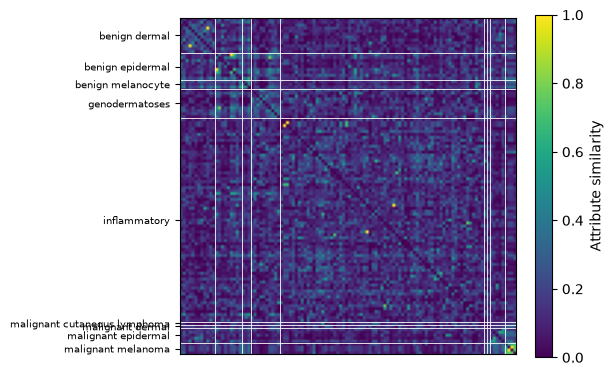

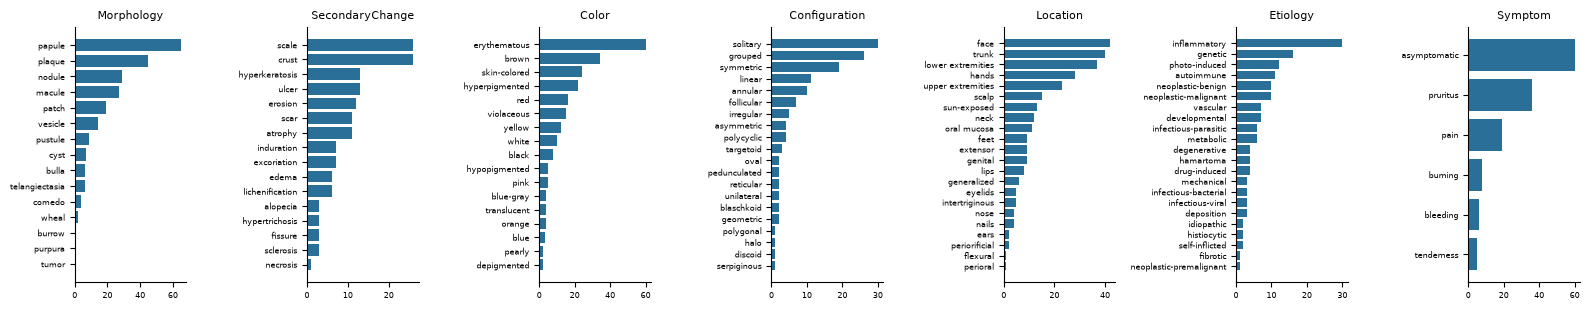

In [8]:
# similarity heatmap ordered by category
o = np.lexsort((tax['disease'], tax['category']))
fig, ax = plt.subplots(figsize=(6.2, 5.6))
im = ax.imshow(S[np.ix_(o, o)], cmap='viridis', vmin=0, vmax=1)
cats = tax['category'].to_numpy()[o]
b = [0] + [i for i in range(1, len(cats)) if cats[i] != cats[i - 1]] + [len(cats)]
for x in b[1:-1]:
    ax.axhline(x - .5, color='w', lw=.6); ax.axvline(x - .5, color='w', lw=.6)
mid = [(b[i] + b[i + 1]) / 2 - .5 for i in range(len(b) - 1)]
labels = [cats[b[i]] for i in range(len(b) - 1)]
ax.set_yticks(mid, labels, fontsize=7); ax.set_xticks([])
plt.colorbar(im, ax=ax, fraction=.046, label='Attribute similarity')
plt.tight_layout()
for ext in ('pdf', 'png'):
    plt.savefig(FIG / f'kg_similarity.{ext}', dpi=300, bbox_inches='tight')
plt.show()

# attribute usage per type
fig, axes = plt.subplots(1, len(VOCAB), figsize=(16, 3.2))
for ax, f in zip(axes, VOCAB):
    t = SCHEMA[f][0]
    cols_f = [c for c in attr_nodes if c.startswith(t + ':')]
    cnt = attr_df[cols_f].sum().sort_values()
    ax.barh([c.split(':', 1)[1] for c in cnt.index], cnt.values, color='#2a6f97')
    ax.set_title(t, fontsize=8); ax.tick_params(labelsize=6)
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
for ext in ('pdf', 'png'):
    plt.savefig(FIG / f'kg_attribute_usage.{ext}', dpi=300, bbox_inches='tight')
plt.show()

## 5. Disease text

In [9]:
# three text views per disease for text encoders:
#   name_text  : the label only (CLIP-style baseline prompt)
#   attr_text  : generated from the KG attributes only
#   full_text  : attributes plus the curated description
def phrase(xs):
    xs = list(xs)
    return '' if not xs else xs[0] if len(xs) == 1 else ', '.join(xs[:-1]) + ' and ' + xs[-1]

rows = []
for _, r in tax.iterrows():
    e = kbi.loc[alias2kb[r['disease']]]
    g = {f: split(e[f]) for f in VOCAB}
    parts = [f"{r['disease']} is a {phrase(g['etiology'])} skin condition in the {r['category']} group."]
    if g['primary']:
        parts.append(f"Lesions are {phrase(g['color'])} {phrase(g['primary'])}"
                     + (f" with {phrase(g['secondary'])}" if g['secondary'] else '') + '.')
    if g['configuration']:
        parts.append(f"Arrangement: {phrase(g['configuration'])}.")
    if g['location']:
        parts.append(f"Typical sites: {phrase(g['location'])}.")
    if g['symptom']:
        parts.append(f"Symptoms: {phrase(g['symptom'])}.")
    attr_text = ' '.join(parts)
    rows.append(dict(disease_id=r['disease_id'], disease=r['disease'],
                     name_text=f"a clinical photograph of {r['disease']}",
                     attr_text=attr_text, description=e['description'],
                     full_text=attr_text + ' ' + e['description']))
text = pd.DataFrame(rows)
print(text.loc[0, 'full_text'])

becker nevus is a hamartoma skin condition in the benign dermal group. Lesions are brown and hyperpigmented patch and plaque with hypertrichosis. Arrangement: solitary and unilateral. Typical sites: trunk and upper extremities. Symptoms: asymptomatic. Unilateral brown patch on the shoulder or upper trunk, often with increased hair, appearing in adolescent males.


## 6. Export

In [10]:
nodes.to_csv(OUT / 'nodes.csv', index=False)
edges.to_csv(OUT / 'edges.csv', index=False)
attr_df.to_csv(OUT / 'disease_attributes.csv', index=False)
np.save(OUT / 'disease_similarity.npy', S.astype(np.float32))
text.to_csv(OUT / 'disease_text.csv', index=False)

# per-relation edge indices with type-local node ids (PyTorch Geometric HeteroData)
local = {}
for t, g in nodes.groupby('type'):
    if t == 'Disease':          # Disease ids follow disease_id from 01
        local.update({D[d]: int(i) for d, i in zip(tax['disease'], tax['disease_id'])})
    else:
        local.update({n: i for i, n in enumerate(g['node_id'])})
ntype = dict(zip(nodes['node_id'], nodes['type']))
hetero = {}
for (rel), g in edges.groupby('relation'):
    ht, tt = ntype[g['head'].iat[0]], ntype[g['tail'].iat[0]]
    hetero[f'{ht}__{rel}__{tt}'] = np.array([[local[h] for h in g['head']], [local[t] for t in g['tail']]])
    hetero[f'{ht}__{rel}__{tt}__weight'] = g['weight'].to_numpy(np.float32)
for t, g in nodes.groupby('type'):
    hetero[f'names__{t}'] = (tax.sort_values('disease_id')['disease'].to_numpy() if t == 'Disease'
                             else g['name'].to_numpy())
np.savez(OUT / 'hetero.npz', **hetero)

G = nx.MultiDiGraph()
for n, t, name in nodes.itertuples(index=False):
    G.add_node(n, type=t, name=name)
for h, r, t, w, s in edges.itertuples(index=False):
    G.add_edge(h, t, relation=r, weight=w, source=s)
nx.write_graphml(G, OUT / 'dermkg_v2.graphml')

summary = dict(nodes=len(nodes), edges=len(edges),
               node_types=nodes['type'].value_counts().to_dict(),
               relations=edges['relation'].value_counts().to_dict(),
               validation_issues=issues, quality=QC,
               sim_topk=SIM_TOPK, sim_min=SIM_MIN)
json.dump(summary, open(OUT / 'kg_summary.json', 'w'), indent=2, default=str)
print(f'{len(nodes)} nodes | {len(edges)} edges | {edges.relation.nunique()} relations')
print('hetero keys:', [k for k in hetero if not k.endswith('weight') and not k.startswith('names')])

244 nodes | 2412 edges | 13 relations
hetero keys: ['Disease__BELONGS_TO__Category', 'Disease__DIFFERENTIAL_OF__Disease', 'Disease__HAS_COLOR__Color', 'Disease__HAS_CONFIGURATION__Configuration', 'Disease__HAS_ETIOLOGY__Etiology', 'Disease__HAS_MORPHOLOGY__Morphology', 'Disease__HAS_SECONDARY__SecondaryChange', 'Disease__HAS_SYMPTOM__Symptom', 'Category__IS_A__SuperCategory', 'Disease__LOCATED_AT__Location', 'Disease__SIMILAR_TO__Disease', 'Disease__SUBTYPE_OF__Disease', 'Disease__SYNONYM_OF__Disease']


## 7. Interactive views (optional, needs `pyvis`)

In [11]:
try:
    from pyvis.network import Network
except ImportError:
    Network = None
    print('pyvis not installed, skipping')

COLORS = {'Disease': '#c1121f', 'Category': '#6a4c93', 'SuperCategory': '#3d348b',
          'Morphology': '#2a6f97', 'SecondaryChange': '#61a5c2', 'Color': '#f4a261',
          'Configuration': '#2a9d8f', 'Location': '#8ab17d', 'Etiology': '#e9c46a', 'Symptom': '#bc6c25'}

def view(node_ids, fname, rels=None):
    if Network is None:
        return
    net = Network(height='720px', width='100%', directed=True, cdn_resources='in_line')
    sub = edges[edges['head'].isin(node_ids) | edges['tail'].isin(node_ids)]
    if rels:
        sub = sub[sub['relation'].isin(rels)]
    for n in set(sub['head']) | set(sub['tail']):
        t = ntype[n]
        net.add_node(n, label=n.split(':', 1)[1], color=COLORS.get(t, '#999'), title=t,
                     size=18 if n in node_ids else 10)
    for h, r, t, w, _ in sub.itertuples(index=False):
        net.add_edge(h, t, title=f'{r} ({w:.2f})', label=r if len(sub) < 40 else '')
    net.write_html(str(FIG / fname))
    print('saved', FIG / fname)

view([D['psoriasis']], 'kg_psoriasis.html')
view(list(D.values()), 'kg_diseases_taxonomy.html',
     rels=['BELONGS_TO', 'IS_A', 'SUBTYPE_OF', 'DIFFERENTIAL_OF'])

saved figures_v2\kg_psoriasis.html
saved figures_v2\kg_diseases_taxonomy.html
